In [1]:
import pandas as pd 
train = pd.read_csv('train-selected-columns.csv')
test = pd.read_csv('test-selected-columns.csv')

train.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500


In [2]:
train.shape

(891, 10)

In [3]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
dtypes: float64(2), int64(5), object(3)
memory usage: 69.7+ KB


In [4]:
train.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [5]:
train.isna().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
dtype: int64

In [6]:
train['Survived'].value_counts()

Survived
0    549
1    342
Name: count, dtype: int64

In [7]:
train['Sex'].value_counts()

Sex
male      577
female    314
Name: count, dtype: int64

In [8]:
train.groupby('Sex')['Survived'].value_counts()

Sex     Survived
female  1           233
        0            81
male    0           468
        1           109
Name: count, dtype: int64

In [9]:
train.groupby('Sex')['Survived'].mean()

Sex
female    0.742038
male      0.188908
Name: Survived, dtype: float64

In [10]:
train.groupby(['Sex' , 'Pclass'])['Survived'].mean()

Sex     Pclass
female  1         0.968085
        2         0.921053
        3         0.500000
male    1         0.368852
        2         0.157407
        3         0.135447
Name: Survived, dtype: float64

In [11]:
train.groupby(['Sex' , 'Pclass']).size()

Sex     Pclass
female  1          94
        2          76
        3         144
male    1         122
        2         108
        3         347
dtype: int64

<Axes: >

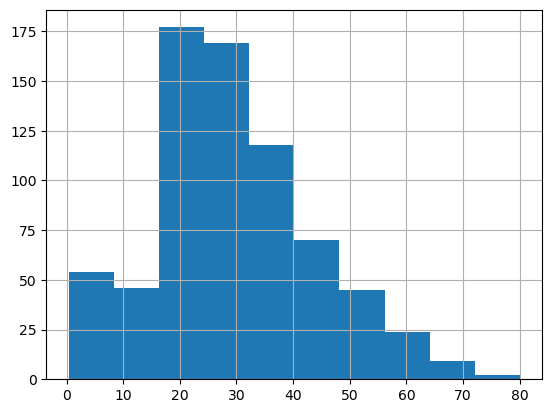

In [12]:
train['Age'].hist()

<Axes: >

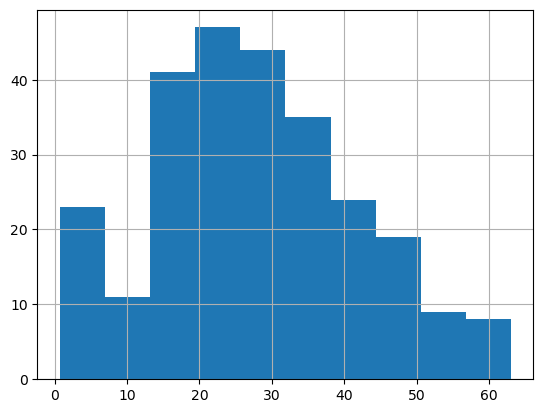

In [13]:
train[train['Sex']=='female']['Age'].hist()

<Axes: >

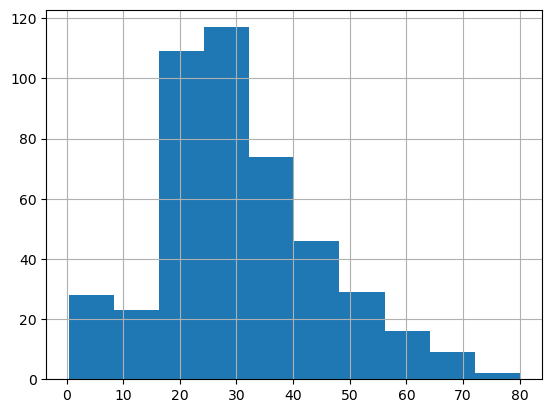

In [14]:
train[train['Sex']=='male']['Age'].hist()

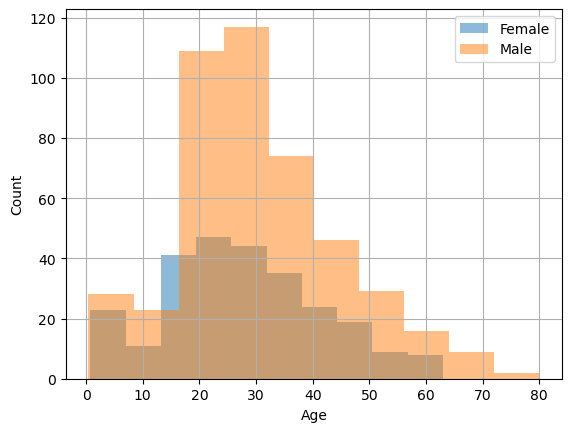

In [15]:
import matplotlib.pyplot as plt 

train[train['Sex'] == 'female']['Age'].hist(alpha=0.5 , label='Female')

train[train['Sex']  == 'male']['Age'].hist(alpha=0.5 , label = 'Male')

plt.xlabel('Age')
plt.ylabel('Count')
plt.legend()
plt.show()

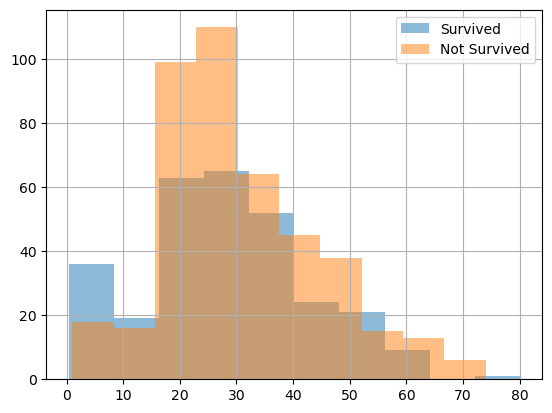

In [16]:
train[train['Survived'] == 1]['Age'].hist(alpha= 0.5 , label = 'Survived')
train[train['Survived']== 0 ]['Age'].hist(alpha = 0.5 , label = 'Not Survived')
plt.legend()
plt.show()

In [17]:
train.groupby('Survived')['Age'].mean()

Survived
0    30.626179
1    28.343690
Name: Age, dtype: float64

In [18]:
train.groupby('Pclass')['Survived'].mean()

Pclass
1    0.629630
2    0.472826
3    0.242363
Name: Survived, dtype: float64

In [19]:
train.groupby(['Sex','Pclass'])['Survived'].mean()

Sex     Pclass
female  1         0.968085
        2         0.921053
        3         0.500000
male    1         0.368852
        2         0.157407
        3         0.135447
Name: Survived, dtype: float64

In [20]:
train.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
dtype: int64

In [21]:
train['Age'] =  train['Age'].fillna(train['Age']).median()

In [22]:
train['Age'].isnull().sum()

np.int64(0)

In [23]:
train.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare'],
      dtype='object')

In [24]:
train.groupby('Survived')['Fare'].mean()

Survived
0    22.117887
1    48.395408
Name: Fare, dtype: float64

<Axes: xlabel='Survived'>

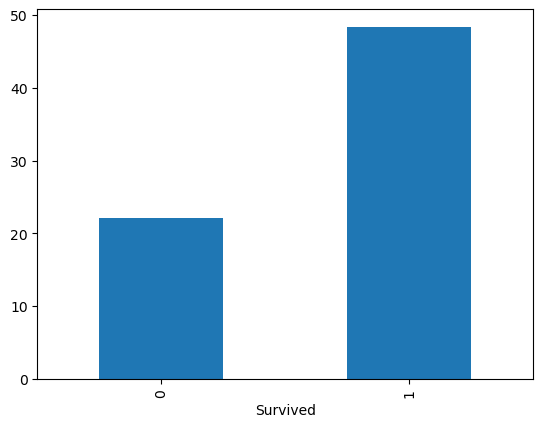

In [25]:
train.groupby('Survived')['Fare'].mean().plot(kind='bar')

In [26]:
train.groupby('Pclass')['Fare'].mean()

Pclass
1    84.154687
2    20.662183
3    13.675550
Name: Fare, dtype: float64

In [27]:
train.groupby('Pclass')['Survived'].mean()

Pclass
1    0.629630
2    0.472826
3    0.242363
Name: Survived, dtype: float64

In [28]:
 train.groupby(['Pclass','Sex'])['Survived'].mean()

Pclass  Sex   
1       female    0.968085
        male      0.368852
2       female    0.921053
        male      0.157407
3       female    0.500000
        male      0.135447
Name: Survived, dtype: float64

In [29]:
train.groupby('SibSp')['Survived'].mean()

SibSp
0    0.345395
1    0.535885
2    0.464286
3    0.250000
4    0.166667
5    0.000000
8    0.000000
Name: Survived, dtype: float64

In [30]:
train.groupby('SibSp')['Survived'].agg(['mean' , 'count'])

,mean,count
SibSp,,
0,0.345395,608
1,0.535885,209
2,0.464286,28
3,0.250000,16
4,0.166667,18
5,0.000000,5
8,0.000000,7


In [31]:
train.groupby('Parch')['Survived'].agg(['mean','count'])

,mean,count
Parch,,
0,0.343658,678
1,0.550847,118
2,0.500000,80
3,0.600000,5
4,0.000000,4
5,0.200000,5
6,0.000000,1


In [32]:
train['FamilySize'] = train['SibSp'] + train['Parch'] + 1

train.groupby('FamilySize')['Survived'].agg(['mean' , 'count'])

,mean,count
FamilySize,,
1,0.303538,537
2,0.552795,161
3,0.578431,102
4,0.724138,29
5,0.200000,15
6,0.136364,22
7,0.333333,12
8,0.000000,6
11,0.000000,7


In [33]:
train.groupby('Survived')['Fare'].agg(['mean','count'])

,mean,count
Survived,,
0,22.117887,549
1,48.395408,342


In [34]:
train['FareGroup'] = pd.qcut(train['Fare'], q = 3 , labels = ['Low', 'Mediume' , ' High'])
train.groupby('FareGroup')['Survived'].agg(['mean', 'count'])

C:\Users\ProShop\AppData\Local\Temp\ipykernel_14832\2958763488.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  train.groupby('FareGroup')['Survived'].agg(['mean', 'count'])


,mean,count
FareGroup,,
Low,0.198052,308
Mediume,0.402778,288
High,0.559322,295


In [35]:
train.groupby('Pclass')['Fare'].agg(['mean' ,'median' , 
                                     'count'])
    

,mean,median,count
Pclass,,,
1,84.154687,60.2875,216
2,20.662183,14.2500,184
3,13.675550,8.0500,491


In [36]:
train.groupby('Pclass')['Survived'].agg(['mean', 'count'])



,mean,count
Pclass,,
1,0.629630,216
2,0.472826,184
3,0.242363,491


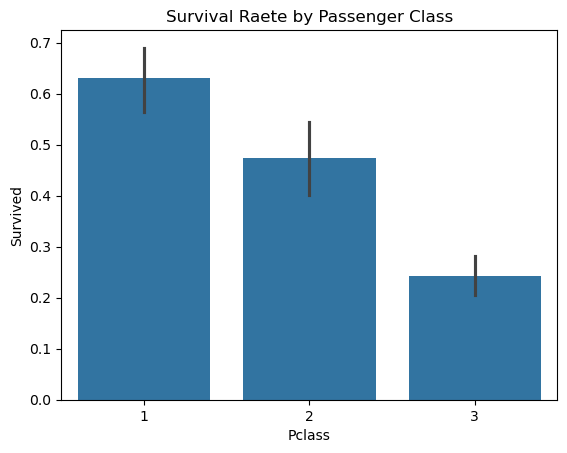

In [37]:
import seaborn as sns
import matplotlib.pyplot as plt 

sns.barplot(data=train , x ='Pclass' , y = 'Survived')
plt.title('Survival Raete by Passenger Class')
plt.show()

In [38]:
train['IsAlone'] = (train['FamilySize'] == 1).astype(int)
train[['FamilySize' , 'IsAlone']]. head()

,FamilySize,IsAlone
0,2,0
1,2,0
2,1,1
3,2,0
4,1,1


In [39]:
train['Title'] = train['Name'].str.extract(r",\s*([^.]*)\.")

train[['Name' , 'Title']].head()

,Name,Title
0,"Braund, Mr. Owen Harris",Mr
1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",Mrs
2,"Heikkinen, Miss. Laina",Miss
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",Mrs
4,"Allen, Mr. William Henry",Mr


In [40]:
train['Title'].value_counts()

Title
Mr              517
Miss            182
Mrs             125
Master           40
Dr                7
Rev               6
Mlle              2
Major             2
Col               2
the Countess      1
Capt              1
Ms                1
Sir               1
Lady              1
Mme               1
Don               1
Jonkheer          1
Name: count, dtype: int64

In [41]:
train["Title"] = train["Title"].replace({
    "Mlle": "Miss",
    "Ms": "Miss",
    "Mme": "Mrs",
    "Don": "Rare",
    "Capt": "Rare",
    "Major": "Rare",
    "Col": "Rare",
    "Rev": "Rare",
    "Sir": "Rare",
    "Lady": "Rare",
    "Jonkheer": "Rare",
    "the Countess": "Rare"
})



In [42]:
train['Title'].value_counts()

Title
Mr        517
Miss      185
Mrs       126
Master     40
Rare       16
Dr          7
Name: count, dtype: int64

In [43]:
train.groupby('Title')['Survived'].mean()

Title
Dr        0.428571
Master    0.575000
Miss      0.702703
Mr        0.156673
Mrs       0.793651
Rare      0.312500
Name: Survived, dtype: float64

In [44]:
pd.get_dummies(train['Title'],dtype=int)

,Dr,Master,Miss,Mr,Mrs,Rare
0,0,0,0,1,0,0
1,0,0,0,0,1,0
2,0,0,1,0,0,0
3,0,0,0,0,1,0
4,0,0,0,1,0,0
...,...,...,...,...,...,...
886,0,0,0,0,0,1
887,0,0,1,0,0,0
888,0,0,1,0,0,0
889,0,0,0,1,0,0


In [45]:
title_encoded = pd.get_dummies(train['Title'], dtype=int)

train = pd.concat([train , title_encoded] , axis = 1)

title_encoded.head()

,Dr,Master,Miss,Mr,Mrs,Rare
0,0,0,0,1,0,0
1,0,0,0,0,1,0
2,0,0,1,0,0,0
3,0,0,0,0,1,0
4,0,0,0,1,0,0


In [46]:
train = train.drop('Title' , axis = 1)

In [47]:
train.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'FamilySize', 'FareGroup', 'IsAlone', 'Dr',
       'Master', 'Miss', 'Mr', 'Mrs', 'Rare'],
      dtype='object')

In [48]:
conditions = [ train['FamilySize'] <= 3 ,train['FamilySize'] <= 5 , train['FamilySize'] > 5  ]

In [49]:
import numpy as np 

choices = ['Small', 'Mediume' , 'Large']

train['FamilyGroup'] = np.select(conditions , choices , default = 'Unknown')

In [50]:
train['Ticket'].value_counts().head(10)

Ticket
347082          7
CA. 2343        7
1601            7
3101295         6
CA 2144         6
347088          6
S.O.C. 14879    5
382652          5
LINE            4
PC 17757        4
Name: count, dtype: int64

In [51]:
train['TicketGroupSize'] = train['Ticket'].map(train['Ticket'].value_counts())

In [52]:
train[['Ticket', 'TicketGroupSize']].head(10)

,Ticket,TicketGroupSize
0,A/5 21171,1
1,PC 17599,1
2,STON/O2. 3101282,1
3,113803,2
4,373450,1
5,330877,1
6,17463,1
7,349909,4
8,347742,3
9,237736,2


In [53]:
train['FarePerPerson'] = train ['Fare'] / train['TicketGroupSize']

train[['Fare' ,'FarePerPerson' , 'TicketGroupSize']].head(10)

,Fare,FarePerPerson,TicketGroupSize
0,7.2500,7.25000,1
1,71.2833,71.28330,1
2,7.9250,7.92500,1
3,53.1000,26.55000,2
4,8.0500,8.05000,1
5,8.4583,8.45830,1
6,51.8625,51.86250,1
7,21.0750,5.26875,4
8,11.1333,3.71110,3
9,30.0708,15.03540,2


In [54]:
train.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'FamilySize', 'FareGroup', 'IsAlone', 'Dr',
       'Master', 'Miss', 'Mr', 'Mrs', 'Rare', 'FamilyGroup', 'TicketGroupSize',
       'FarePerPerson'],
      dtype='object')

In [55]:
train = train.drop(['PassengerId' , 'Name' , 'Ticket'] , axis = 1)

In [56]:
train.columns

Index(['Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare',
       'FamilySize', 'FareGroup', 'IsAlone', 'Dr', 'Master', 'Miss', 'Mr',
       'Mrs', 'Rare', 'FamilyGroup', 'TicketGroupSize', 'FarePerPerson'],
      dtype='object')

In [57]:
train.dtypes

Survived              int64
Pclass                int64
Sex                  object
Age                 float64
SibSp                 int64
Parch                 int64
Fare                float64
FamilySize            int64
FareGroup          category
IsAlone               int64
Dr                    int64
Master                int64
Miss                  int64
Mr                    int64
Mrs                   int64
Rare                  int64
FamilyGroup          object
TicketGroupSize       int64
FarePerPerson       float64
dtype: object

In [58]:
train['Sex'] = train['Sex'].map({'female' : 0 , 'male' : 1})

In [59]:
train['Sex'].head()

0    1
1    0
2    0
3    0
4    1
Name: Sex, dtype: int64

In [60]:
pd.get_dummies(train['FamilyGroup'] , dtype = int )

,Large,Mediume,Small
0,0,0,1
1,0,0,1
2,0,0,1
3,0,0,1
4,0,0,1
...,...,...,...
886,0,0,1
887,0,0,1
888,0,1,0
889,0,0,1


In [61]:
train['FamilyGroup'].value_counts()

FamilyGroup
Small      800
Large       47
Mediume     44
Name: count, dtype: int64

In [62]:
family_encoded = pd.get_dummies(train['FamilyGroup'] , dtype = int)

train = pd.concat([train , family_encoded] , axis = 1 )

In [63]:
train = train.drop('FamilyGroup' , axis = 1)

In [64]:
train.columns

Index(['Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare',
       'FamilySize', 'FareGroup', 'IsAlone', 'Dr', 'Master', 'Miss', 'Mr',
       'Mrs', 'Rare', 'TicketGroupSize', 'FarePerPerson', 'Large', 'Mediume',
       'Small'],
      dtype='object')

In [65]:
fare_encoded = pd.get_dummies(train['FareGroup'] , dtype = int )
fare_encoded.head()

,Low,Mediume,High
0,1,0,0
1,0,0,1
2,1,0,0
3,0,0,1
4,1,0,0


In [66]:
train = pd.concat([train , fare_encoded] , axis = 1)

train = train.drop('FareGroup' , axis =1)
train.columns

Index(['Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare',
       'FamilySize', 'IsAlone', 'Dr', 'Master', 'Miss', 'Mr', 'Mrs', 'Rare',
       'TicketGroupSize', 'FarePerPerson', 'Large', 'Mediume', 'Small', 'Low',
       'Mediume', ' High'],
      dtype='object')

In [67]:
y = train['Survived']

X = train.drop('Survived' , axis = 1)

In [68]:
X.shape

(891, 22)

In [69]:
y.shape

(891,)

In [70]:
from sklearn.model_selection import train_test_split 
X_train, X_test, y_train, y_test= train_test_split( X , y , test_size=0.2 , random_state=42)

In [71]:
X_train.shape

(712, 22)

In [72]:
X_test.shape

(179, 22)

In [73]:
X_train.dtypes

Pclass               int64
Sex                  int64
Age                float64
SibSp                int64
Parch                int64
Fare               float64
FamilySize           int64
IsAlone              int64
Dr                   int64
Master               int64
Miss                 int64
Mr                   int64
Mrs                  int64
Rare                 int64
TicketGroupSize      int64
FarePerPerson      float64
Large                int64
Mediume              int64
Small                int64
Low                  int64
Mediume              int64
 High                int64
dtype: object

In [74]:
from sklearn.ensemble import RandomForestClassifier 

model = RandomForestClassifier( n_estimators = 100 , random_state = 42)

model.fit(X_train , y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [75]:
predictions = model.predict(X_test)

In [76]:
predictions[:20]

array([1, 0, 0, 1, 0, 1, 1, 0, 1, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0])

In [77]:
y_test[:20]

709    1
439    0
840    0
720    1
39     1
290    1
300    1
333    0
208    1
136    1
137    0
696    0
485    0
244    0
344    0
853    1
621    1
653    1
886    0
110    0
Name: Survived, dtype: int64

In [78]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test , predictions)

accuracy

0.8100558659217877

In [79]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test , predictions)
cm

array([[90, 15],
       [19, 55]])

In [80]:
from sklearn.metrics import classification_report

print(classification_report(y_test , predictions))

              precision    recall  f1-score   support

           0       0.83      0.86      0.84       105
           1       0.79      0.74      0.76        74

    accuracy                           0.81       179
   macro avg       0.81      0.80      0.80       179
weighted avg       0.81      0.81      0.81       179



In [81]:
model.feature_importances_

array([0.04804842, 0.15435836, 0.        , 0.0264455 , 0.01952079,
       0.17421335, 0.03991865, 0.00924908, 0.00270341, 0.01598216,
       0.0329411 , 0.14090982, 0.03293112, 0.00896839, 0.0573694 ,
       0.17450495, 0.00883361, 0.0064958 , 0.00793845, 0.01339302,
       0.00957196, 0.01570269])

In [82]:
feature_importance = pd.Series(model.feature_importances_ , index = X.columns).sort_values(ascending= False)

feature_importance

FarePerPerson      0.174505
Fare               0.174213
Sex                0.154358
Mr                 0.140910
TicketGroupSize    0.057369
Pclass             0.048048
FamilySize         0.039919
Miss               0.032941
Mrs                0.032931
SibSp              0.026445
Parch              0.019521
Master             0.015982
 High              0.015703
Low                0.013393
Mediume            0.009572
IsAlone            0.009249
Rare               0.008968
Large              0.008834
Small              0.007938
Mediume            0.006496
Dr                 0.002703
Age                0.000000
dtype: float64

In [83]:
model_depth5 =RandomForestClassifier(n_estimators = 100 , max_depth= 5 , random_state=42)

model_depth5.fit(X_train , y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,5
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [84]:
predictions_depth5 = model_depth5.predict(X_test)


In [85]:
accuracy_depth_5 = accuracy_score(y_test , predictions_depth5)

accuracy_depth_5

0.8324022346368715

In [86]:
for depth in [2, 3, 4, 5, 6, 8, 10, None]:
    model_test = RandomForestClassifier(
        n_estimators=100,
        max_depth=depth,
        random_state=42
    )
    
    model_test.fit(X_train, y_train)
    
    predictions_test = model_test.predict(X_test)
    
    accuracy_test = accuracy_score(y_test, predictions_test)
    
    print(depth, accuracy_test)

2 0.7988826815642458
3 0.8212290502793296
4 0.8324022346368715
5 0.8324022346368715
6 0.8212290502793296
8 0.8268156424581006
10 0.8268156424581006
None 0.8100558659217877


In [87]:
for n in[10 , 50 , 100 , 200 , 300] :
    model_test= RandomForestClassifier(n_estimators = n , max_depth= 5 , random_state=42)

    model_test.fit(X_train,y_train)

    predictions_test = model_test.predict(X_test)

    accuracy_test= accuracy_score(y_test ,predictions_test)

    print(n , accuracy_test)

10 0.8212290502793296
50 0.8212290502793296
100 0.8324022346368715
200 0.8268156424581006
300 0.8268156424581006


In [89]:
final_model = RandomForestClassifier(n_estimators = 100 , max_depth= 5 , random_state=42)

final_model.fit(X_train , y_train)

final_prediction = final_model.predict(X_test)

print(classification_report(y_test , final_prediction))

              precision    recall  f1-score   support

           0       0.84      0.88      0.86       105
           1       0.81      0.77      0.79        74

    accuracy                           0.83       179
   macro avg       0.83      0.82      0.83       179
weighted avg       0.83      0.83      0.83       179



In [91]:
cm_final = confusion_matrix(y_test , final_prediction)

print(cm_final)

[[92 13]
 [17 57]]


In [94]:
TN , TP , FN , FP = cm_final.ravel()
print('TN' , TN)
print('TP' , TP)
print('FN' , FN)
print('FP' , FP)

TN 92
TP 13
FN 17
FP 57


In [97]:
train_accuracy = final_model.score(X_train , y_train)

test_accuracy = final_model.score(X_test , y_test)

print('Train_accuracy' , train_accuracy)

print('Test_accuracy' , test_accuracy )

Train_accuracy 0.8553370786516854
Test_accuracy 0.8324022346368715


In [98]:
from sklearn.model_selection import cross_val_score

In [100]:
cv_scores = cross_val_score(final_model , X_train , y_train , cv = 5 , scoring = 'accuracy')

cv_scores

array([0.85314685, 0.83916084, 0.79577465, 0.80985915, 0.85211268])

In [101]:
cv_mean = cv_scores.mean()

print ('Cross_Validation_Accuracy:' , cv_mean)

Cross_Validation_Accuracy: 0.8300108342361863
